# ***CT5146: Introduction to NLP (Online)***

# ***Assignment 2: Counter-Narrative Generation*** (Total 100 marks)
This assignment focuses on **Counter-Narrative Generation** for hate speech.

A Counter-Narrative (CN) is a non-aggressive response that offers feedback
through fact-bound arguments and is considered as
the most effective approach to withstand hate messages

---

###  **Student Details**

Enter your

**Name:** Marcin Byra

**Student ID:** 25258161

---

>  <font color="red">**Disclaimer:** This assignment may contain hate speech and offensive content, strictly for academic purposes. </font>

---
**Deadline:** **`06:45 PM, 23rd October, 2026`** (Ireland Time)

**Submission Format:** `.ipynb`

**Individual Assignment:** This is an individual assignment - your work must be your own.

<!-- ---

### 🚫 Academic Integrity

<font color="red">**Strictly no Generative AI.**</font> Do the assignment by yourself - write code and answers fully in your own words, without using AI tools.

<font color="red">**Note:**</font> You must **disable the AI features on Google Colab** before working on this assignment.
📺 Guide: [How to disable AI in Colab](https://youtu.be/qrGZv8nPh1o) -->



---

## **Task Roadmap**

| # | Section | Focus | Marks |
|---|---|---|---:|
| 1 | **Dataset & Task Understanding** | Explore the hate-speech / counter-narrative dataset | **30** |
| 2️ | **Counter-Narrative Generation Method** | Build instruction-based LLM generation and evaluate responses | **40** |
| 3️ | **Improving Generation & Comparison** | Implement an improvement (e.g., RAG) and compare performance | **30** |
|  |  | **Total** | **100** |

Each section builds on the previous one:

**Dataset → Generation Method → Improving Generation & Comparison**

## Dataset

This assignment must use a **Counter-Narrative Generation dataset**.

You may choose **one of the example datasets listed below**, or use another appropriate publicly available counter-narrative dataset.

### Example Datasets

*   Multitarget-CONAN - https://drive.google.com/file/d/1dueNK0SnRidLmuLhUfErmDWb0cWZcQ0W/view?usp=sharing
*   CONAN - https://drive.google.com/file/d/1aSWImoHwNgRnKME18cJn8BMg9C5pjlgH/view?usp=sharing
*   Counter-Narrative-ENG - https://drive.google.com/file/d/1IQuhXKsR-ueB2MCS-I3K3GGKN3wbMKpO/view?usp=sharing
*   Multitarget-CONAN - https://drive.google.com/file/d/1MY4jIHdDa0YhXHNWctP0YrzfemyLuigL/view?usp=sharing

If you choose a different dataset, it should contain, or be easily mapped to, the following information:

- `HATE_SPEECH` — a hateful statement;
- `COUNTER_NARRATIVE` — a human-written counter-narrative;
- `TARGET` — the target group of the hate speech.

> You will use the **training data** for building the generation method and retrieval examples, and the **test data** only for final evaluation.

Tutorial: [Loading a CSV using Hugging Face Datasets library](https://huggingface.co/docs/datasets/tabular_load#csv-files)

# Installing and Importing Packages

> **Note:** You may use any packages required for your experiments.

# Installing and Importing Packages

> **Note:** This is a setup cell and is not directly graded. You may install and import any Python packages required for your experiments.  
> Commonly useful libraries may include `pandas`, `numpy`, `matplotlib`, `transformers`, `torch`, `sentence-transformers`, and `evaluate`.

In [ ]:
!pip install -q bitsandbytes evaluate rouge_score bert_score sentence-transformers

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 3.5 MB/s eta 0:00:00


In [ ]:
#Colab already includes `torch`, `transformers`, `pandas`, `matplotlib` and `scikit-learn`.

import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

#llm
import torch
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, pipeline, set_seed

import evaluate
from sentence_transformers import SentenceTransformer, util

#for judge asnwers
import json

#hide long warnings
transformers.logging.set_verbosity_error()
#long txt in tables
pd.set_option("display.max_colwidth", 200)

### Settings

All settings are in one cell, each explained by its comment. The most important is `N_TEST = 100`: the brief asks for a test subset, and 100 items give stable averages while keeping the runtime manageable on a T4.

In [ ]:
RANDOM_SEED = 42
set_seed(RANDOM_SEED)


TEST_SIZE = 0.2
#no of test hate speech
N_TEST = 100

#llms
#conternarrative
MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"
#judge
JUDGE_MODEL_NAME = "Qwen/Qwen2.5-7B-Instruct"
#retrieval (Section 3)
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

# gen settings
#counternarrative max lenght
MAX_NEW_TOKENS = 120
#max judge answer
JUDGE_MAX_NEW_TOKENS = 150
#no of retrieved examples
K_EXAMPLES = 3
COMPUTE_DTYPE = torch.float16




---

# **Section 1: Dataset & Counter-Narrative Task Understanding**

### `Total = 30 marks`
Before you touch any code, pick your dataset and get to know it. This section is about **choosing well and showing you understand what you chose.** You can either use the below given datasets, or find relevant dataset.

Before generating counter-narratives, you first need to understand the dataset and the relationship between the **hate-speech input** and the **counter-narrative response**.

In this section, you will inspect the dataset, explore its main characteristics, visualise important patterns, and explain what you observe.

| Task | What you'll do | Marks |
|---|---|---:|
| **1a** | Inspect the dataset | `10` |
| **1c** | Perform text analysis and visualisation | `10` |
| **1d** | Explain your observations | `10` |

>  The goal of this section is to understand the data before building the generation system in the next section.

#**1a: Dataset (Explore hate-speech targets and response characteristics)** (10 marks)
Load your chosen dataset, count the occurrences of each target category, and compute summary statistics (lengths) of both hate speech and counter-narratives.

I chose Multitarget-CONAN:
- it has the three required columns: `HATE_SPEECH`, `COUNTER_NARRATIVE` and `TARGET`;
- it covers 8 target groups
- it is in **English**
- its counter-narratives were provided by NGI experts

In [ ]:

DATA_URL = (
    "https://raw.githubusercontent.com/marcoguerini/CONAN/master/"
    "Multitarget-CONAN/Multitarget-CONAN.csv"
)
df = pd.read_csv(DATA_URL)

# df.info() lists every column with its number of non-empty values and its data type,
# so it shows the size of the table and whether any values are missing.
df.info()
df.head()   # show the first 5 rows

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5003 entries, 0 to 5002
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   INDEX              5003 non-null   int64 
 1   HATE_SPEECH        5003 non-null   object
 2   COUNTER_NARRATIVE  5003 non-null   object
 3   TARGET             5003 non-null   object
 4   VERSION            5003 non-null   object
dtypes: int64(1), object(4)
memory usage: 195.6+ KB


,INDEX,HATE_SPEECH,COUNTER_NARRATIVE,TARGET,VERSION
0,0,Maybe the UN could talk to those asian and african nations responsible for 90%+ of the pollution in the oceans' instead of insisting on this bullshit about climate change.,"You're right, ocean pollution is one of the main environmental problems we face, however, climate change is a global problem, and everyone should help to combat it, no matter where in the world yo...",other,V1
1,1,"‘Juice (Jews) are worse that nukes.’ Caption to a meme showing Hiroshima 1945 and present day, contrast against pictures of Detroit in 1945 and present day.’",You'd rather be nuked then?,JEWS,V1
2,2,Foreigners on UK benefits leaps 41% in 5 years with over 400K now handed payouts. This nonsense has got to stop.,"You seem to be worried about government expenditure… it has actually been shown that,over time, migration reduces pressure on government spending – because migrants are more likely to be young adu...",MIGRANTS,V1
3,3,"Jews cannot be patriots, since their allegiance will always be to the state of Israel.","You can have parents and grandparents born elsewhere, and still be a patriot for the country you were born in.",JEWS,V1
4,4,"Israel, Zionism and Jewish Supremacist control of America are the main causes of terrorism, instability and conflict in the world. All other theories are diversions from this ultimate truth.",Wouldn't you say its colonialism from many different countries and the consequesequences of Western intervention abroad which led to a lot of radicalisation and extremism?,JEWS,V1


In [ ]:
###cleaning
# only needed columns
df = df[["HATE_SPEECH", "COUNTER_NARRATIVE", "TARGET"]].copy()
rows_before = len(df)

for column in ["HATE_SPEECH", "COUNTER_NARRATIVE", "TARGET"]:
    df[column] = df[column].str.strip()
df = df.drop_duplicates()
df = df.reset_index(drop=True)

rows_after = len(df)
print("Rows before cleaning:", rows_before)
print("Rows after cleaning: ", rows_after)

Rows before cleaning: 5003
Rows after cleaning:  5002


### Train / test split by hate speech

Many hate speeches appear several times, each with a different counter-narrative. A random split of the rows could put the same hate speech in both parts. The retrieval in Section 3 would then find it and copy its human reply (**data leakage**).

So we split the **unique hate speeches** 80/20 with `train_test_split`, stratified by target so both parts have the same target mix, and every row follows its hate speech. As the brief requires, the training part provides the retrieval examples and the test part is used only for the final evaluation.

In [ ]:
# One row per unique hate speech, together with its target group
unique_hate_speech = df.drop_duplicates(subset="HATE_SPEECH")[["HATE_SPEECH", "TARGET"]]

train_hate_speech, test_hate_speech = train_test_split(
    unique_hate_speech,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=unique_hate_speech["TARGET"],
)

# .isin() = true for rows which hate speech was put in the test part
is_test_row = df["HATE_SPEECH"].isin(test_hate_speech["HATE_SPEECH"])
test_df = df[is_test_row].reset_index(drop=True)
train_df = df[~is_test_row].reset_index(drop=True)

print("Train:", len(train_df), "rows,", len(train_hate_speech), "unique hate speeches")
print("Test: ", len(test_df), "rows,", len(test_hate_speech), "unique hate speeches")

#  this must be 0, otherwise leakage.
overlap = set(train_df["HATE_SPEECH"]).intersection(set(test_df["HATE_SPEECH"]))
print("Hate speeches that appear in BOTH train and test:", len(overlap))

Train: 4052 rows, 2974 unique hate speeches
Test:  950 rows, 744 unique hate speeches
Hate speeches that appear in BOTH train and test: 0


In [ ]:
#pair counts per target group
target_counts = df["TARGET"].value_counts()
target_percent = df["TARGET"].value_counts(normalize=True) * 100
target_table = pd.DataFrame({"count": target_counts, "percent": target_percent.round(1)})
display(target_table)

,count,percent
TARGET,,
MUSLIMS,1335,26.7
MIGRANTS,956,19.1
WOMEN,662,13.2
LGBT+,617,12.3
JEWS,594,11.9
POC,352,7.0
other,266,5.3
DISABLED,220,4.4


In [ ]:
#count words
df["hate_speech_words"] = df["HATE_SPEECH"].str.split().str.len()
df["counter_narrative_words"] = df["COUNTER_NARRATIVE"].str.split().str.len()
#count characters
df["hate_speech_chars"] = df["HATE_SPEECH"].str.len()
df["counter_narrative_chars"] = df["COUNTER_NARRATIVE"].str.len()

length_columns = ["hate_speech_words", "counter_narrative_words",
                  "hate_speech_chars", "counter_narrative_chars"]
print("Summary statistics of lengths:")
display(df[length_columns].describe().round(1))

Summary statistics of lengths:


,hate_speech_words,counter_narrative_words,hate_speech_chars,counter_narrative_chars
count,5002.0,5002.0,5002.0,5002.0
mean,13.2,24.8,75.5,140.7
std,7.8,11.4,44.4,66.9
min,2.0,1.0,11.0,8.0
25%,8.0,17.0,43.0,97.0
50%,12.0,23.0,66.0,130.0
75%,17.0,30.0,95.0,171.0
max,68.0,149.0,379.0,956.0


In [ ]:
#rows per hate speech
replies_per_hate_speech = df.groupby("HATE_SPEECH").size()
n_unique = len(replies_per_hate_speech)
n_with_several = (replies_per_hate_speech > 1).sum()
most_replies = replies_per_hate_speech.max()
print("Unique hate speeches:", n_unique)
print("Hate speeches with more than one counter-narrative:", n_with_several)
print("Most counter-narratives for one hate speech:", most_replies)

Unique hate speeches: 3718
Hate speeches with more than one counter-narrative: 535
Most counter-narratives for one hate speech: 55


# **1b: Text analysis and Visualization** (10 marks)
Create two clear, labeled plots: a bar chart or any diagram showing hate target distributions, and a distribution comparison of input vs. response text lengths.


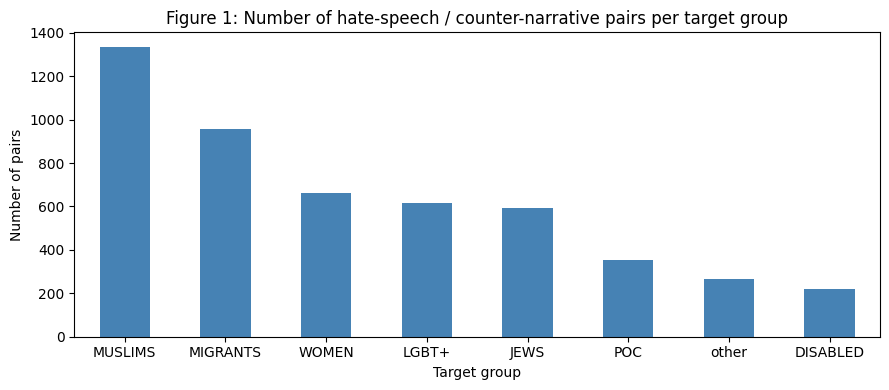

In [ ]:
#number of pairs per target group (input hate speech and output counter narrative)
target_counts.plot(kind="bar", figsize=(9, 4), color="steelblue", rot=0)
plt.title("Figure 1: Number of hate-speech / counter-narrative pairs per target group")
plt.xlabel("Target group")
plt.ylabel("Number of pairs")
plt.tight_layout()
plt.show()

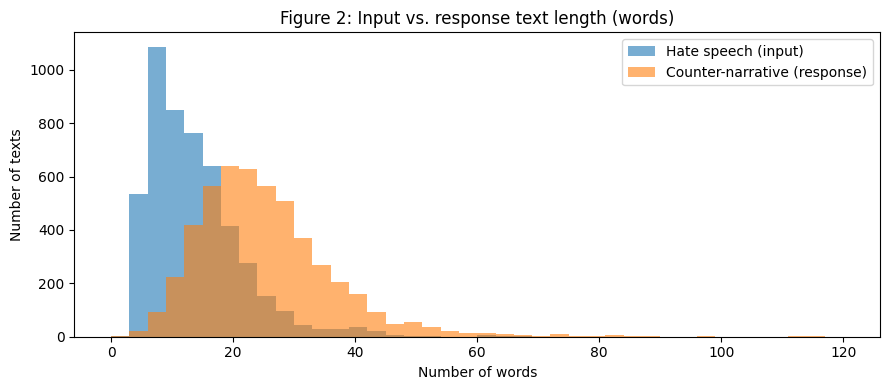

In [ ]:
#histogram
plt.figure(figsize=(9, 4))
plt.hist(df["hate_speech_words"], bins=40, range=(0, 120), alpha=0.6, label="Hate speech (input)")
plt.hist(df["counter_narrative_words"], bins=40, range=(0, 120), alpha=0.6,
         label="Counter-narrative (response)")
plt.title("Figure 2: Input vs. response text length (words)")
plt.xlabel("Number of words")
plt.ylabel("Number of texts")
plt.legend()
plt.tight_layout()
plt.show()

**Key findings:**
- **Imbalanced targets (Figure 1):** Muslims make up 26.7% of the pairs, disabled people only 4.4%.
- **Replies are about twice as long as the hate speech (Figure 2):** 24.8 versus 13.2 words on average, and their lengths vary more. Three quarters of the replies have 30 words or fewer.
- **One hate speech, many valid replies:** 535 of the 3,718 hate speeches have several counter-narratives (up to 55). So we evaluate against all references, and we expect low word-overlap scores even for good replies.

# **1c: Explanations** (10 marks)

**Question:** Explain your dataset selection and your data analysis process.

Include:

- target distribution;
- text-length differences;
- one important observation from your visualisations;
- one challenge for counter-narrative generation.

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
I chose Multitarget-CONAN. It's in English, written by NGO experts, multiple target groups.
Targets are imbalanced (Muslims 27%, disabled 4%). Counter-narratives are twice as long as hate speech (25 versus 13 words).
Hate speech may have several valid responses, generating specific counter-narrative reply might be challenging, requires very good understanding of main issue.
```

---

# **Section 2: Instruction-Based LLM Counter-Narrative Generation**

### `Total = 40 marks`

In this section, you will build the main **counter-narrative generation method** using a **pre-trained open-source instruction-tuned Large Language Model (LLM)**.

You will use the model in **inference-only mode**, which means you are **not required to train, fine-tune, or update the model parameters**. Your main focus is on designing a suitable instruction/prompt, generating counter-narratives, and evaluating the generated responses.

| Task | What you'll do | Marks |
|---|---|---:|
| **2a** | Build an instruction-based counter-narrative generation method using an open-source LLM | `20` |
| **2b** | Evaluate the generated counter-narratives | `10` |
| **2c** | Explain your method and results | `10` |

>  The goal of this section is to understand how effectively a pre-trained LLM can generate suitable counter-narratives using only clear instructions and prompting, without additional model training.

# **2a: Build an Instruction-based Counter-Narrative Generation** (20 marks)
Initialize an open-source instruction LLM and write a prompt template to generate non-aggressive, fact-bound counter-narratives on a test subset.

In [ ]:
# 4-bit settings, the same as in lab lecture 7
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
)

def load_llm(model_name):
    """tokenizer with 4-bit model"""
    print("Loading", model_name, "in 4-bit ...")
    llm_tokenizer = AutoTokenizer.from_pretrained(model_name)
    llm_model = AutoModelForCausalLM.from_pretrained(
        model_name,
        quantization_config=bnb_config,
        device_map="auto",
    )
    llm_pipeline = pipeline("text-generation", model=llm_model, tokenizer=llm_tokenizer)
    return llm_tokenizer, llm_pipeline

tokenizer, generator = load_llm(MODEL_NAME)

Loading Qwen/Qwen2.5-3B-Instruct in 4-bit ...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'TypeError: Failed to fetch'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

### Prompt design

The prompt follows the starter-kit structure (Task → Rules → Comment → "Counter-narrative:"), with these additions from the prompting lecture:
- **Persona** in the system message: an experienced counter-speech operator at an anti-discrimination NGO (AUTOMAT "Act as", L6 p.66).
- **Target group** named in the task, so the reply addresses the right group.
- **Rules** for the brief's "non-aggressive, fact-bound": answer the specific claim, stay calm and respectful, use only widely accepted facts.
- **Fail case:** if unsure about a fact, give no numbers and argue from shared values instead (L6 p.51). This reduces hallucination.
- **Length limit:** 2–3 sentences (max 60 words), close to the human replies (about 25 words).

No examples are given (**zero-shot**): this is the baseline. The rules are stored once in `RULES` and reused unchanged in Section 3.

In [ ]:
# a bit of formatting
TARGET_DESCRIPTIONS = {
    "MUSLIMS": "Muslims",
    "MIGRANTS": "migrants",
    "WOMEN": "women",
    "LGBT+": "LGBT+ people",
    "JEWS": "Jewish people",
    "POC": "people of colour",
    "DISABLED": "disabled people",
    "other": "a group of people",
}

# define persona and behaviour
SYSTEM_PROMPT = (
    "You are an experienced counter-speech operator at an anti-discrimination NGO. "
    "You write calm, respectful replies to hateful online comments. "
    "Your replies correct false claims with widely accepted facts, "
    "appeal to empathy and shared values, and never insult anyone."
)

# Rules
RULES = """Rules:
- Respond directly to the specific claim made in the comment.
- Be calm, respectful and non-aggressive. Use neutral, respectful words (no slurs or insults).
- Only use facts that are widely accepted.
  If you are not sure a fact is correct, do not give numbers; argue from shared values and empathy instead.
- Write 2 to 3 sentences (maximum 60 words).
- Provide only the counter-narrative, without any introduction or label."""

def build_zero_shot_prompt(hate_speech, target):
    """Build the zero-shot user prompt for one hate speech (Section 2)."""
    target_text = TARGET_DESCRIPTIONS.get(target, "a group of people")
    prompt = f"""Task: Write a counter-narrative response to the hateful comment below.
The comment targets {target_text}.

{RULES}

Comment:
{hate_speech}

Counter-narrative:"""
    return prompt

In [ ]:
#apply chat template, generate and return new text
def generate_text(llm_tokenizer, llm_pipeline, system_prompt, user_prompt, max_new_tokens):
    """Send one prompt to an instruction-tuned LLM and return only the generated answer."""
    messages = []
    if system_prompt is not None:
        messages.append({"role": "system", "content": system_prompt})
    messages.append({"role": "user", "content": user_prompt})

    prompt_text = llm_tokenizer.apply_chat_template(messages, tokenize=False,
                                                    add_generation_prompt=True)

    outputs = llm_pipeline(
        prompt_text,
        max_new_tokens=max_new_tokens,
        #greedy decoding
        do_sample=False,
        return_full_text=False,
    )
    answer = outputs[0]["generated_text"]
    return answer.strip()

#remove labels and quotes from reply
def clean_output(text):
    """Remove labels/quotes the model sometimes adds around its answer."""
    text = text.strip()
    for label in ["Counter-narrative:", "Counter-Narrative:", "Counter narrative:", "Response:"]:
        if text.startswith(label):
            text = text[len(label):]
            text = text.strip()
    text = text.strip('"“”')
    return text.strip()

#for refusal rate
REFUSAL_PHRASES = [
    "i can't help", "i cannot help", "i can't assist", "i cannot assist",
    "i won't", "i will not", "as an ai", "i'm unable to",
]

def is_refusal(text):
    """Return True if the reply looks like a refusal (or is empty)."""
    if text.strip() == "":
        return True
    start = text[:150].lower()
    start = start.replace("’", "'")
    for phrase in REFUSAL_PHRASES:
        if phrase in start:
            return True
    return False

In [ ]:
#limit to N_TEST random sample fo hate speeches, with all related experts written counter narrative
test_subset = test_hate_speech.sample(n=N_TEST, random_state=RANDOM_SEED)

test_items = []
for hate_speech, target in zip(test_subset["HATE_SPEECH"], test_subset["TARGET"]):
    rows_for_this_hate_speech = test_df[test_df["HATE_SPEECH"] == hate_speech]
    item = {
        "hate_speech": hate_speech,
        "target": target,
        "references": list(rows_for_this_hate_speech["COUNTER_NARRATIVE"]),
    }
    test_items.append(item)

print("Number of test items used:", len(test_items))
print("Example item:", test_items[0])

Number of test items used: 100
Example item: {'hate_speech': 'Most immigrants in the U.S. are criminals.', 'target': 'MIGRANTS', 'references': ['Not all immigrants are criminals. And it is important to consider that 13.5% of the US population is composed of migrants that are here legally.']}


In [ ]:
##check on one example

# zero-shot prompt on first training example
example_row = train_df.iloc[0]
example_prompt = build_zero_shot_prompt(example_row["HATE_SPEECH"], example_row["TARGET"])
example_answer = generate_text(tokenizer, generator, SYSTEM_PROMPT, example_prompt, MAX_NEW_TOKENS)
example_output = clean_output(example_answer)

print("HATE SPEECH:     ", example_row["HATE_SPEECH"])
print("TARGET:          ", example_row["TARGET"])
print("GENERATED:       ", example_output)
print("HUMAN REFERENCE: ", example_row["COUNTER_NARRATIVE"])
print("Refusal?         ", is_refusal(example_output))

HATE SPEECH:      ‘Juice (Jews) are worse that nukes.’ Caption to a meme showing Hiroshima 1945 and present day, contrast against pictures of Detroit in 1945 and present day.’
TARGET:           JEWS
GENERATED:        The comparison to nuclear weapons is extreme and not accurate. However, both groups have faced significant hardships throughout history. Let's focus on the shared humanity and work towards understanding and unity.
HUMAN REFERENCE:  You'd rather be nuked then?
Refusal?          False


In [ ]:
###zero-shot replies for test subset

def make_results_table(items, predictions):
    """Put inputs, references and predictions in one DataFrame (one row per test item)."""
    rows = []
    for item, prediction in zip(items, predictions):
        rows.append({
            "hate_speech": item["hate_speech"],
            "target": item["target"],
            "human_reference": item["references"][0],
            "number_of_references": len(item["references"]),
            "prediction": prediction,
            "refusal": is_refusal(prediction),
        })
    return pd.DataFrame(rows)

baseline_predictions = []
for item in tqdm(test_items, desc="Zero-shot generation"):
    prompt = build_zero_shot_prompt(item["hate_speech"], item["target"])
    answer = generate_text(tokenizer, generator, SYSTEM_PROMPT, prompt, MAX_NEW_TOKENS)
    baseline_predictions.append(clean_output(answer))

baseline_df = make_results_table(test_items, baseline_predictions)
baseline_df.to_csv("section2_zero_shot_outputs.csv", index=False)
print("Saved section2_zero_shot_outputs.csv")

Zero-shot generation:   0%|          | 0/100 [00:00<?, ?it/s]

Saved section2_zero_shot_outputs.csv


# **2b: Evaluate Counter-Narratives** (10 marks)
Evaluate your generated responses against human ground truths using quantitative NLP metrics like BLEU, ROUGE, BERTScore and so on. Also evaluate using rubric-based scores on generated counter narrative.

In [ ]:
#quantitative NLP metrics
#each reply is compared with all human conuter narratives
#bleu and rouge counts overlap (shared words and sequences)
#bertscore F1 compares meaning

bleu_metric = evaluate.load("bleu")
rouge_metric = evaluate.load("rouge")
bertscore_metric = evaluate.load("bertscore")

def lowercase_all(texts):
    lowered = []
    for text in texts:
        lowered.append(text.lower())
    return lowered

def compute_reference_scores(predictions, items):
    """BLEU, ROUGE and BERTScore against all human references"""
    references = []
    lower_references = []
    for item in items:
        references.append(item["references"])
        lower_references.append(lowercase_all(item["references"]))

    bleu_result = bleu_metric.compute(predictions=lowercase_all(predictions),
                                      references=lower_references)
    rouge_result = rouge_metric.compute(predictions=predictions, references=references)
    bert_result = bertscore_metric.compute(predictions=predictions, references=references,
                                           lang="en", rescale_with_baseline=True)

    per_example_bertscore = bert_result["f1"]
    scores = {
        "BLEU": bleu_result["bleu"],
        "ROUGE-1": rouge_result["rouge1"],
        "ROUGE-2": rouge_result["rouge2"],
        "ROUGE-L": rouge_result["rougeL"],
        "BERTScore-F1": sum(per_example_bertscore) / len(per_example_bertscore),
    }
    return scores, per_example_bertscore

In [ ]:
#LLM as a judge; larger model Qwen2.5-7B scores replies on scale 1 to 5
#assesment criteria: relevance, tone (calm, respectful), factuality, clarity

judge_tokenizer, judge_generator = load_llm(JUDGE_MODEL_NAME)

RUBRIC = {
    "relevance": "5 = directly refutes the specific claim with a concrete argument or example, "
                 "4 = addresses the specific claim but with a general argument, "
                 "3 = partly addresses the claim, mostly a general defence of the group, "
                 "2 = generic statement about respect or tolerance that ignores the claim, "
                 "1 = off-topic, or agrees with or repeats the hateful claim",
    "tone": "5 = calm, respectful and empathetic, not preachy, "
            "4 = respectful but somewhat lecturing or preachy, "
            "3 = noticeably moralising or condescending, "
            "2 = harsh or sarcastic, "
            "1 = insulting or aggressive",
    "factuality": "5 = every statement is accurate, or clearly presented as opinion or values, "
                  "4 = accurate overall but includes a broad generalisation, "
                  "3 = vague claims presented as facts that cannot be checked, "
                  "2 = at least one doubtful claim or statistic, "
                  "1 = clearly false or invented facts or statistics",
    "clarity": "5 = clear, concise and well structured, "
               "4 = clear with minor awkwardness, "
               "3 = understandable but wordy or awkward, "
               "2 = hard to follow, "
               "1 = incoherent or ungrammatical",
}

#both text or numeric
VALID_SCORES = [1, 2, 3, 4, 5, "1", "2", "3", "4", "5"]

# exact answer format
JUDGE_JSON_FORMAT = ('{"critique": "<one sentence>", "relevance": <1-5>, "tone": <1-5>, '
                     '"factuality": <1-5>, "clarity": <1-5>}')

def build_judge_prompt(hate_speech, counter_narrative):
    rubric_lines = ""
    for criterion, description in RUBRIC.items():
        rubric_lines += f"- {criterion}: {description}\n"

    prompt = f"""You are a strict expert evaluator of counter-narratives (replies to hate speech).
Most replies are acceptable but not excellent, so use the whole scale:
5 = excellent (rare), 4 = good, 3 = acceptable, 2 = weak, 1 = very poor.

Hateful comment:
{hate_speech}

Counter-narrative to evaluate:
{counter_narrative}

Scoring guide:
{rubric_lines}
First write one sentence of critique that names the main weakness of the counter-narrative.
Then give the scores. Answer with JSON only, in exactly this format:
{JUDGE_JSON_FORMAT}"""
    return prompt


# I used AI google gemini to help me with parsing code
# answeres not always followed specific format
def parse_judge_answer(judge_answer):
    """Read the judge's JSON answer. Returns (scores, critique).
    Missing or invalid scores become None."""
    scores = {}
    for criterion in RUBRIC:
        scores[criterion] = None                  # default: no valid score found
    critique = ""

    start = judge_answer.find("{")                # position of the first "{"
    end = judge_answer.rfind("}")                 # position of the last "}"
    if start == -1 or end == -1:
        return scores, critique                   # no JSON in the answer

    json_text = judge_answer[start:end + 1]       # cut out the part between { and }
    try:
        data = json.loads(json_text)
    except json.JSONDecodeError:
        return scores, critique                   # the JSON was broken
    if not isinstance(data, dict):
        return scores, critique

    critique = str(data.get("critique", ""))
    for criterion in RUBRIC:
        value = data.get(criterion)
        if value in VALID_SCORES:
            scores[criterion] = int(value)
    return scores, critique

#judge scores every prediction
def judge_all(items, predictions):
    all_scores = []
    all_critiques = []
    n_failed = 0
    for i in tqdm(range(len(items)), desc="Judging"):
        prompt = build_judge_prompt(items[i]["hate_speech"], predictions[i])
        answer = generate_text(judge_tokenizer, judge_generator, None, prompt, JUDGE_MAX_NEW_TOKENS)
        scores, critique = parse_judge_answer(answer)
        if None in scores.values():
            n_failed += 1
        all_scores.append(scores)
        all_critiques.append(critique)
    print("Judge answers that could not be read completely:", n_failed)
    judgements = pd.DataFrame(all_scores, dtype=float)
    return judgements, all_critiques

#score one method with every measure
#return average scores, per example BERT F1, judge score, critique
def evaluate_method(predictions, results_df, csv_name):
    reference_scores, bertscores = compute_reference_scores(predictions, test_items)
    judgements, critiques = judge_all(test_items, predictions)

    # format per-example rubric scores,critie and reply sid eby side
    for criterion in RUBRIC:
        results_df["rubric_" + criterion] = judgements[criterion]
    results_df["rubric_critique"] = critiques
    results_df.to_csv(csv_name, index=False)

    # combined dictionary for avergaes: reference score, refusal rate, rubric
    scores = {}
    scores.update(reference_scores)
    scores["Refusal rate"] = results_df["refusal"].mean()
    criterion_averages = judgements.mean()
    for criterion in RUBRIC:
        scores["Rubric " + criterion] = criterion_averages[criterion]
    scores["Rubric overall (1-5)"] = criterion_averages.mean()
    return scores, bertscores, judgements, critiques

Loading Qwen/Qwen2.5-7B-Instruct in 4-bit ...


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

In [ ]:
# Score replies with every metric
section2_scores, baseline_bertscores, baseline_judgements, baseline_critiques = evaluate_method(
    baseline_predictions, baseline_df, "section2_zero_shot_outputs.csv")

section2_table = pd.DataFrame({"Section 2: zero-shot": section2_scores})
display(section2_table.round(3))

# score distribution
score_table = pd.DataFrame({
    "relevance": baseline_judgements["relevance"].value_counts(),
    "tone": baseline_judgements["tone"].value_counts(),
    "factuality": baseline_judgements["factuality"].value_counts(),
    "clarity": baseline_judgements["clarity"].value_counts(),
})
# a score that never occurs gets 0
score_table = score_table.fillna(0).astype(int)
score_table = score_table.sort_index()
# natural numbers, no decimal dot
score_table.index = score_table.index.astype(int)
score_table.index.name = "score"
print("How often each score (1-5) was given in Section 2:")
display(score_table)

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

Judging:   0%|          | 0/100 [00:00<?, ?it/s]

Judge answers that could not be read completely: 0


,Section 2: zero-shot
BLEU,0.008
ROUGE-1,0.147
ROUGE-2,0.014
ROUGE-L,0.108
BERTScore-F1,0.254
Refusal rate,0.000
Rubric relevance,3.090
Rubric tone,4.040
Rubric factuality,4.950
Rubric clarity,4.050


How often each score (1-5) was given in Section 2:


,relevance,tone,factuality,clarity
score,,,,
2,2,0,0,0
3,87,0,0,0
4,11,96,5,95
5,0,4,95,5


# **2c: Explanation** (10 marks)
**Question:** Briefly explain your instruction-based LLM generation method and the results.

Include:

- why you chose the LLM;
- how you designed the prompt;
- what the evaluation scores used and why;
- one strength and one limitation of the generated counter-narratives.

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
I used Qwen2.5-3B-Instruct because it is open-source and fits free colab hardware T4.
The prompt sets a persona, rules, fail case and length limit.
BLEU/ROUGE check word overlap - 0.008/0.11 low,
BERTScore confirms respinses on topic but wording different than exaperts
Strength: respectful replies - tone 4.0/5,, no refusals. Limitation: generic arguments - relevance 3.1/5.
**I used google gemini to help me with parsing judge asnwers in json**
```

---

# **Section 3: Improving the Counter-Narrative Generation Method**

### `Total = 30 marks`

In this section, you will improve the counter-narrative generation method developed in Section 2.

You may choose **one suitable recent improvement technique** that you believe can improve the quality of the generated counter-narratives. The improvement should build on the same general LLM-based generation approach used in Section 2.

Possible examples include:

- improved or structured prompting;
- semantic retrieval / Retrieval-Augmented Generation (RAG);

You should clearly explain **what you changed, why you changed it, and how the change is expected to improve the generation quality**.

| Task | What you'll do | Marks |
|---|---|---:|
| **3a** | Implement one suitable improvement to the Section 2 generation method | `15` |
| **3b** | Evaluate and compare the improved method with the original method from Section 2 | `10` |
| **3c** | Explain your improvement method and findings | `5` |

>  The goal of this section is not to use one specific technique, but to investigate whether a well-motivated improvement can produce better counter-narratives. Your marks will be based on the quality of the improvement, the evaluation, and how clearly you justify and explain your approach.

# **3a: Improve the methods** (15 marks)
Apply an advanced improvement technique (e.g., RAG, or structured few-shot examples) to generate better responses.


In [ ]:
#improvement: RAG supported zero shot prompting
#all-MiniLM-L6-v2 turns every training hate speech into vector
#util.sematic_search retusn text with hihest cosine similarity

#retrieve 3 most similar hate speech examples with their asnwers and put in prompt as reference
#examples show llm how good response looks like
#new replies are expected to be more siilar to expert take and more relevant



print("Loading embedding model", EMBEDDING_MODEL_NAME, "...")
embedder = SentenceTransformer(EMBEDDING_MODEL_NAME)

train_texts = list(train_df["HATE_SPEECH"])
train_replies = list(train_df["COUNTER_NARRATIVE"])


# normalize embeddings to give each vector lenght 1
train_embeddings = embedder.encode(train_texts, convert_to_tensor=True,
                                   normalize_embeddings=True, show_progress_bar=True)
embedding_shape = tuple(train_embeddings.shape)
print("Embedding matrix shape (texts, numbers per text):", embedding_shape)

Loading embedding model sentence-transformers/all-MiniLM-L6-v2 ...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/127 [00:00<?, ?it/s]

Embedding matrix shape (texts, numbers per text): (4052, 384)


In [ ]:
def retrieve_examples(hate_speech, k=K_EXAMPLES):
    """return the k most similar TRAINING pairs, here k=3 set in settings"""
    query_embedding = embedder.encode(hate_speech, convert_to_tensor=True,
                                      normalize_embeddings=True)

    # semantic search returns one result list per query
    # 5 candidates for each example, duplicates  removed
    hits = util.semantic_search(query_embedding, train_embeddings, top_k=k * 5)[0]

    examples = []
    used_texts = set()
    for hit in hits:
        position = hit["corpus_id"]
        similar_text = train_texts[position]
        #skip repeared hate speech
        if similar_text in used_texts:
            continue
        used_texts.add(similar_text)
        examples.append({
            "hate_speech": similar_text,
            "counter_narrative": train_replies[position],
            # cosine similarity
            "similarity": hit["score"],
        })
        if len(examples) == k:
            break
    return examples

In [ ]:
#RAG prompt

def build_rag_prompt(hate_speech, target, examples):
    #build rag few-shot prompt
    target_text = TARGET_DESCRIPTIONS.get(target, "a group of people")
    # most similar example last
    ordered_examples = list(reversed(examples))
    examples_text = ""
    for number, example in enumerate(ordered_examples, start=1):
        example_comment = example["hate_speech"]
        example_reply = example["counter_narrative"]
        examples_text += f"Example {number}\n"
        examples_text += f"Comment: {example_comment}\n"
        examples_text += f"Counter-narrative: {example_reply}\n\n"

    prompt = f"""Task: Write a counter-narrative response to the hateful comment below.
The comment targets {target_text}.

Here are examples of good counter-narratives written by NGO experts for similar comments.
Use them as a guide for tone, length and kind of arguments, but write a new reply that fits the new comment.

{examples_text}{RULES}

Comment:
{hate_speech}

Counter-narrative:"""
    return prompt

In [ ]:
#prompt now contains retrieved examples
rag_predictions = []
# similarity of the best retrieved example
best_similarities = []

for item in tqdm(test_items, desc="Retrieval few-shot generation"):
    examples = retrieve_examples(item["hate_speech"])
    prompt = build_rag_prompt(item["hate_speech"], item["target"], examples)
    answer = generate_text(tokenizer, generator, SYSTEM_PROMPT, prompt, MAX_NEW_TOKENS)
    rag_predictions.append(clean_output(answer))
    best_similarities.append(examples[0]["similarity"])

rag_df = make_results_table(test_items, rag_predictions)
rag_df["best_example_similarity"] = best_similarities
rag_df.to_csv("section3_rag_outputs.csv", index=False)
print("Saved section3_rag_outputs.csv")

average_similarity = rag_df["best_example_similarity"].mean()
print(f"Average similarity of the best retrieved example: {average_similarity:.3f}")

Retrieval few-shot generation:   0%|          | 0/100 [00:00<?, ?it/s]

Saved section3_rag_outputs.csv
Average similarity of the best retrieved example: 0.802


# **3b: Evaluate the improved method** (10  marks)
Evaluate the new outputs using the same metrics from Section 2b and display a side-by-side performance comparison table.

In [ ]:
# score retrieval replies
section3_scores, rag_bertscores, rag_judgements, rag_critiques = evaluate_method(
    rag_predictions, rag_df, "section3_rag_outputs.csv")

Judging:   0%|          | 0/100 [00:00<?, ?it/s]

Judge answers that could not be read completely: 0


In [ ]:
comparison = pd.DataFrame({
    "Section 2: zero-shot": section2_scores,
    "Section 3: retrieval few-shot": section3_scores,
})
comparison["Difference (3 - 2)"] = (comparison["Section 3: retrieval few-shot"]
                                    - comparison["Section 2: zero-shot"])
print("Higher is better for all rows except 'Refusal rate' (lower is better).")
display(comparison.round(3))

Higher is better for all rows except 'Refusal rate' (lower is better).


,Section 2: zero-shot,Section 3: retrieval few-shot,Difference (3 - 2)
BLEU,0.008,0.016,0.008
ROUGE-1,0.147,0.141,-0.007
ROUGE-2,0.014,0.016,0.002
ROUGE-L,0.108,0.110,0.002
BERTScore-F1,0.254,0.262,0.008
Refusal rate,0.000,0.000,0.000
Rubric relevance,3.090,2.950,-0.140
Rubric tone,4.040,4.050,0.010
Rubric factuality,4.950,4.950,0.000
Rubric clarity,4.050,4.070,0.020


In [ ]:
# per-item BERTScore
n_compared = len(test_items)
n_improved = 0
for zero_shot_score, rag_score in zip(baseline_bertscores, rag_bertscores):
    if rag_score > zero_shot_score:
        n_improved += 1
print(f"Retrieval improved BERTScore for {n_improved} of {n_compared} test items.")

relevance_difference = rag_judgements["relevance"] - baseline_judgements["relevance"]
n_relevance_up = (relevance_difference > 0).sum()
n_relevance_down = (relevance_difference < 0).sum()
print(f"Strict-rubric relevance went up for {n_relevance_up} items and down for {n_relevance_down} items.")

# how many replies got each relevance score
relevance_table = pd.DataFrame({
    "Section 2: zero-shot": baseline_judgements["relevance"].value_counts(),
    "Section 3: retrieval few-shot": rag_judgements["relevance"].value_counts(),
})
relevance_table = relevance_table.fillna(0).astype(int)
relevance_table = relevance_table.sort_index()
relevance_table.index = relevance_table.index.astype(int)
relevance_table.index.name = "relevance score"
display(relevance_table)

Retrieval improved BERTScore for 57 of 100 test items.
Strict-rubric relevance went up for 9 items and down for 23 items.


,Section 2: zero-shot,Section 3: retrieval few-shot
relevance score,,
2,2,17
3,87,71
4,11,12


In [ ]:
# three test items
# both methods side by side

for i in range(3):
    best_example = retrieve_examples(test_items[i]["hate_speech"])[0]
    best_similarity = round(best_example["similarity"], 3)
    print("=" * 100)
    print("HATE SPEECH: ", test_items[i]["hate_speech"])
    print("HUMAN:       ", test_items[i]["references"][0])
    print("ZERO-SHOT:   ", baseline_predictions[i])
    print("   judge:     relevance", baseline_judgements["relevance"][i], "|", baseline_critiques[i])
    print("BEST EXAMPLE:", best_example["hate_speech"], "| similarity", best_similarity)
    print("   its reply: ", best_example["counter_narrative"])
    print("RETRIEVAL:   ", rag_predictions[i])
    print("   judge:     relevance", rag_judgements["relevance"][i], "|", rag_critiques[i])

HATE SPEECH:  Most immigrants in the U.S. are criminals.
HUMAN:        Not all immigrants are criminals. And it is important to consider that 13.5% of the US population is composed of migrants that are here legally.
ZERO-SHOT:    Many immigrants contribute positively to society through hard work and innovation. We should focus on their contributions rather than generalizing based on a small minority.
   judge:     relevance 3.0 | The counter-narrative does not directly address the claim that immigrants are criminals.
BEST EXAMPLE: Immigrants are mainly criminals. | similarity 0.925
   its reply:  There is no evidence that migrants commit more crimes than natives. Do you have any?
RETRIEVAL:    There is no evidence that immigrants in the U.S. are more likely to be criminals than native-born citizens.
   judge:     relevance 4.0 | The counter-narrative does not provide any concrete evidence to support its claim.
HATE SPEECH:  Negroes create social problems so we must get rid of them.
HUM

# **3c: Explanation** (5 marks)

**Question:** Briefly explain your improvement method and whether it improved the counter-narrative generation.

Include:

- what improvement you applied;
- why you selected it;
- how the results changed compared with Section 2;
- one benefit and one limitation of the improved method.

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
I added RAG few-shot prompting: three similar (0.8) training pairs as reference got each reply.
This was to  because zero-shot replies were not very specific.
BERTScore rose slightly from  0.254 to 0.262 for 57/100 items, but strict-rubric relevance fell from 3.09 to 2.95.
Benefit: human expert-like, sometimes more direct replies.
Limitation: replies copied brievity of examples and applied generic style.
```

---

#  That's a wrap!

Thanks for working through this assignment. Double-check your cells run top-to-bottom with saved outputs, then upload to `Canvas` before **06:45 PM, October 23rd, 2026**.

---